## Task 1 Dataset Import

In [10]:
import csv
import importlib.util
import subprocess
import sys
from pathlib import Path

# Detect Colab without making local notebook runs depend on google.colab.
try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

# Colab normally includes PyTorch. Install only the Kaggle client if needed.
if importlib.util.find_spec("kagglehub") is None:
    print("Installing kagglehub...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", "kagglehub"]
    )

import kagglehub
import torch
import torchvision

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if IN_COLAB and not torch.cuda.is_available():
    raise RuntimeError(
        "Colab is not using a CUDA GPU. Select Runtime > Change runtime type > T4 GPU, then rerun this cell."
    )
if torch.cuda.is_available():
    gpu_properties = torch.cuda.get_device_properties(0)
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {gpu_properties.total_memory / 1024**3:.1f} GiB")

# Persist training checkpoints in the shared Google Drive folder on Colab.
# Local runs keep using a repository-local checkpoints directory.
if IN_COLAB:
    drive.mount("/content/drive")
    CHECKPOINT_ROOT = Path(
        "/content/drive/MyDrive/ECSE-551-A2/checkpoints"
    )
else:
    CHECKPOINT_ROOT = Path("./checkpoints")

CNN_CHECKPOINT_DIR = CHECKPOINT_ROOT / "cnn"
VIT_CHECKPOINT_DIR = CHECKPOINT_ROOT / "vit"
CNN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
VIT_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
print("Checkpoint location:", CHECKPOINT_ROOT.resolve())

def find_dataset_problems(data_dir):
    """Return specific problems with the expected RIVAL10 dataset layout."""
    data_dir = Path(data_dir)
    problems = []

    csv_requirements = {
        data_dir / "train.csv": {"image_path", "label_name"},
        data_dir / "test.csv": {"id"},
        data_dir / "sample_submission.csv": {"id", "label_name"},
    }
    for csv_path, required_columns in csv_requirements.items():
        if not csv_path.is_file() or csv_path.stat().st_size == 0:
            problems.append(f"Missing or empty file: {csv_path}")
            continue

        try:
            with csv_path.open(newline="", encoding="utf-8-sig") as file:
                reader = csv.DictReader(file)
                columns = set(reader.fieldnames or [])
                missing_columns = required_columns.difference(columns)
                if missing_columns:
                    problems.append(
                        f"{csv_path} is missing columns: {sorted(missing_columns)}"
                    )
                if next(reader, None) is None:
                    problems.append(f"CSV contains no data rows: {csv_path}")
        except (OSError, UnicodeError, csv.Error) as error:
            problems.append(f"Could not read {csv_path}: {error}")

    image_directories = [
        data_dir / "archive" / "RIVAL10_Kaggle" / "train" / "ordinary",
        data_dir / "archive" / "RIVAL10_Kaggle" / "test" / "test_images",
    ]
    image_extensions = {".jpg", ".jpeg", ".png"}
    for image_directory in image_directories:
        if not image_directory.is_dir():
            problems.append(f"Missing directory: {image_directory}")
            continue
        contains_image = any(
            path.is_file() and path.suffix.lower() in image_extensions
            for path in image_directory.iterdir()
        )
        if not contains_image:
            problems.append(f"Directory contains no images: {image_directory}")

    return problems


data_dir = Path("./data")
dataset_problems = find_dataset_problems(data_dir)

if dataset_problems:
    print("Dataset is missing required content:")
    for problem in dataset_problems:
        print(" -", problem)

    kagglehub.login()
    path = kagglehub.competition_download(
        "fall-2026-ecse-551-task-1",
        output_dir=str(data_dir),
    )

    remaining_problems = find_dataset_problems(data_dir)
    if remaining_problems:
        raise RuntimeError(
            "Dataset download completed, but validation still failed:\n"
            + "\n".join(f"- {problem}" for problem in remaining_problems)
        )
else:
    path = str(data_dir)
    print("Validated existing dataset; skipping download.")

print("Dataset location:", path)

Dataset already exists; skipping download.
Dataset location: data


In [11]:
# Check image dimensions across the extracted dataset (images and masks).
# This reads image headers only; it does not load all pixel data into memory.
# from collections import Counter
# from pathlib import Path

# from PIL import Image

# data_root = Path("./data/archive/RIVAL10_Kaggle")
# image_extensions = {".jpg", ".jpeg", ".png"}

# if not data_root.is_dir():
#     raise FileNotFoundError(f"Dataset directory not found: {data_root.resolve()}")

# size_counts = Counter()
# size_examples = {}
# unreadable = []
# images_checked = 0

# for image_path in data_root.rglob("*"):
#     if not image_path.is_file() or image_path.suffix.lower() not in image_extensions:
#         continue

#     try:
#         with Image.open(image_path) as image:
#             size = image.size  # (width, height)
#     except OSError as error:
#         unreadable.append((image_path, str(error)))
#         continue

#     images_checked += 1
#     size_counts[size] += 1
#     size_examples.setdefault(size, [])
#     if len(size_examples[size]) < 3:
#         size_examples[size].append(image_path.relative_to(data_root))

# if images_checked == 0 and not unreadable:
#     raise FileNotFoundError(f"No supported image files found under {data_root.resolve()}")

# print(f"Readable images checked: {images_checked}")
# print("Image sizes (width, height):")
# for size, count in sorted(size_counts.items(), key=lambda item: (-item[1], item[0])):
#     print(f"  {size}: {count}")

# if len(size_counts) == 1:
#     print("All readable images have the same size.")
#     if unreadable:
#         print("Could not confirm the size of every file because some images were unreadable.")
# elif len(size_counts) > 1:
#     print("Images have different sizes; examples by size:")
#     for size, examples in size_examples.items():
#         print(f"  {size}: {examples}")

# if unreadable:
#     print(f"Unreadable image files: {len(unreadable)}")
#     for image_path, error in unreadable[:10]:
#         print(f"  {image_path.relative_to(data_root)}: {error}")

## Task 1 CNN Model

In [12]:
import torch
import torch.nn as nn


class CNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()

        # 1. Validate classifier settings
        positive_values = {
            "num_classes": num_classes,
        }
        for name, value in positive_values.items():
            if value <= 0:
                raise ValueError(f"{name} must be positive, got {value}")
        if not 0 <= dropout < 1:
            raise ValueError(f"dropout must be in [0, 1), got {dropout}")

        self.num_classes = num_classes

        # 2. Create the convolutional feature extractor
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )

        # 3. Pool each feature map to a fixed 1 x 1 representation
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # 4. Create the classification head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        # 1. Extract spatial features
        x = self.features(x)

        # 2. Convert feature maps to a fixed 128-value image representation
        x = self.pool(x)

        # 3. Produce one raw logit vector for each image in the batch
        logits = self.classifier(x)

        return logits


# 5. Quick mock test: confirm the model accepts a batch of RGB 224 x 224 images
model = CNN(num_classes=10, dropout=0.3)
mock_images = torch.randn(4, 3, 224, 224)
mock_logits = model(mock_images)
print("Mock input shape:", tuple(mock_images.shape))
print("Mock output shape:", tuple(mock_logits.shape))

Mock input shape: (4, 3, 224, 224)
Mock output shape: (4, 10)


### CNN2 Architecture Variant

Use two convolution layers per block before pooling for comparison with the original CNN.

In [21]:
class CNN2(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()

        # 1. Validate classifier settings
        if num_classes <= 0:
            raise ValueError(f"num_classes must be positive, got {num_classes}")
        if not 0 <= dropout < 1:
            raise ValueError(f"dropout must be in [0, 1), got {dropout}")

        self.num_classes = num_classes

        # 2. Create three feature blocks; each learns twice before downsampling
        self.features = nn.Sequential(
            # Block 1: RGB pixels to 32 feature channels
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 32 to 64 feature channels
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 64 to 128 feature channels
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
        )

        # 3. Average each final feature map to one value
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # 4. Map the pooled representation to class logits
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        # 1. Extract features
        x = self.features(x)

        # 2. Convert feature maps to a fixed-size representation
        x = self.pool(x)

        # 3. Return raw class logits
        return self.classifier(x)


# 5. Confirm CNN2 produces 10 logits for each image
cnn2_model = CNN2(num_classes=10, dropout=0.3)
cnn2_logits = cnn2_model(mock_images)
print("CNN2 mock input shape:", tuple(mock_images.shape))
print("CNN2 mock output shape:", tuple(cnn2_logits.shape))

CNN2 mock input shape: (4, 3, 224, 224)
CNN2 mock output shape: (4, 10)


### Mini Dataset Sample (100 Images)

Create a reproducible sample containing 10 image paths from each class.

In [13]:
# 1. Make a reproducible, class-balanced 100-image development sample.
# The original images stay where they are; this cell only records their paths.
import csv
import random
from collections import defaultdict
from pathlib import Path

MINI_SEED = 42
SAMPLES_PER_CLASS = 10
train_csv = Path("./data/train.csv")
archive_root = Path("./data/archive/RIVAL10_Kaggle")

if not train_csv.is_file():
    raise FileNotFoundError(f"Training CSV not found: {train_csv.resolve()}")
if not archive_root.is_dir():
    raise FileNotFoundError(f"Extracted image directory not found: {archive_root.resolve()}")

rows_by_class = defaultdict(list)
with train_csv.open(newline="", encoding="utf-8-sig") as file:
    for row in csv.DictReader(file):
        relative_parts = Path(row["image_path"]).parts
        if not relative_parts or relative_parts[0] != "RIVAL10":
            raise ValueError(f"Unexpected image path in CSV: {row['image_path']}")

        image_path = archive_root.joinpath(*relative_parts[1:])
        if not image_path.is_file():
            raise FileNotFoundError(f"Image listed in CSV was not found: {image_path}")
        rows_by_class[row["label_name"]].append(image_path)

mini_class_names = sorted(rows_by_class)
if len(mini_class_names) != 10:
    raise ValueError(f"Expected 10 classes, found {len(mini_class_names)}: {mini_class_names}")

rng = random.Random(MINI_SEED)
mini_samples = []
for class_name in mini_class_names:
    class_paths = rows_by_class[class_name]
    if len(class_paths) < SAMPLES_PER_CLASS:
        raise ValueError(
            f"Class {class_name!r} has only {len(class_paths)} images; "
            f"need {SAMPLES_PER_CLASS}."
        )
    mini_samples.extend(
        (image_path, class_name)
        for image_path in rng.sample(class_paths, SAMPLES_PER_CLASS)
    )

print(f"Sampled {len(mini_samples)} images ({SAMPLES_PER_CLASS} per class).")
print("Classes:", mini_class_names)
print("Example:", mini_samples[0])

Sampled 100 images (10 per class).
Classes: ['bird', 'car', 'cat', 'deer', 'dog', 'equine', 'frog', 'plane', 'ship', 'truck']
Example: (WindowsPath('data/archive/RIVAL10_Kaggle/train/ordinary/n01532829_n01532829_5113.JPEG'), 'bird')


### Mini CNN Training Smoke Test

Train on the 100-image sample to verify the local pipeline. This experiment is not expected to produce meaningful final results.

In [15]:
# 2. Run a short CNN training/validation smoke test on the 100-image sample.
# This is for checking the pipeline, not for choosing final hyperparameters.
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset

RUN_MINI_SMOKE_TEST = False
MINI_BATCH_SIZE = 16
MINI_EPOCHS = 3
MINI_IMAGE_SIZE = 128
mini_label_to_index = {name: index for index, name in enumerate(mini_class_names)}

# Keep two examples from every class for validation; the other eight train the model.
mini_by_class = defaultdict(list)
for image_path, class_name in mini_samples:
    mini_by_class[class_name].append((image_path, mini_label_to_index[class_name]))

split_rng = random.Random(MINI_SEED)
mini_train_items = []
mini_val_items = []
for class_name in mini_class_names:
    class_items = mini_by_class[class_name].copy()
    split_rng.shuffle(class_items)
    mini_val_items.extend(class_items[:2])
    mini_train_items.extend(class_items[2:])
split_rng.shuffle(mini_train_items)

class ImageDataset(Dataset):
    def __init__(self, items, image_size):
        self.items = items
        self.image_size = image_size

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        image_path, label = self.items[index]
        with Image.open(image_path) as image:
            image = image.convert("RGB").resize(
                (self.image_size, self.image_size), Image.Resampling.BILINEAR
            )
            image_bytes = bytearray(image.tobytes())
        image_tensor = torch.frombuffer(image_bytes, dtype=torch.uint8)
        image_tensor = image_tensor.reshape(self.image_size, self.image_size, 3)
        image_tensor = image_tensor.permute(2, 0, 1).float().div_(255.0)
        return image_tensor, torch.tensor(label, dtype=torch.long)

mini_train_loader = DataLoader(
    ImageDataset(mini_train_items, MINI_IMAGE_SIZE),
    batch_size=MINI_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
mini_val_loader = DataLoader(
    ImageDataset(mini_val_items, MINI_IMAGE_SIZE),
    batch_size=MINI_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mini_model = CNN(num_classes=len(mini_class_names), dropout=0.3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(mini_model.parameters(), lr=1e-3, weight_decay=1e-4)
if RUN_MINI_SMOKE_TEST:
    print(f"Training on {device}: {len(mini_train_items)} train, {len(mini_val_items)} validation images.")
else:
    print("Skipping mini smoke-test training. Set RUN_MINI_SMOKE_TEST = True to enable it.")

for epoch in range(MINI_EPOCHS if RUN_MINI_SMOKE_TEST else 0):
    mini_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for images, labels in mini_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = mini_model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_count += labels.size(0)

    mini_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0
    with torch.no_grad():
        for images, labels in mini_val_loader:
            images, labels = images.to(device), labels.to(device)
            logits = mini_model(images)
            loss = criterion(logits, labels)
            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (logits.argmax(dim=1) == labels).sum().item()
            val_count += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{MINI_EPOCHS} | "
        f"train loss {train_loss_sum / train_count:.4f}, "
        f"train accuracy {train_correct / train_count:.3f} | "
        f"validation loss {val_loss_sum / val_count:.4f}, "
        f"validation accuracy {val_correct / val_count:.3f}"
    )

Training on cpu: 80 train, 20 validation images.
Epoch 1/3 | train loss 2.1741, train accuracy 0.237 | validation loss 2.2914, validation accuracy 0.100
Epoch 2/3 | train loss 1.8577, train accuracy 0.312 | validation loss 2.2748, validation accuracy 0.150
Epoch 3/3 | train loss 1.7937, train accuracy 0.388 | validation loss 2.2536, validation accuracy 0.100


### Medium Dataset Sample (1,000 Images)

Create a reproducible development sample containing 100 training-image paths per class. The original files stay in place.

In [18]:
# 1. Sample 100 paths from each class for the medium-scale experiment.
MEDIUM_SAMPLES_PER_CLASS = 100
MEDIUM_SEED = 42
medium_rng = random.Random(MEDIUM_SEED)
medium_samples = []

for class_name in mini_class_names:
    class_paths = rows_by_class[class_name]
    if len(class_paths) < MEDIUM_SAMPLES_PER_CLASS:
        raise ValueError(
            f"Class {class_name!r} has only {len(class_paths)} images; "
            f"need {MEDIUM_SAMPLES_PER_CLASS}."
        )
    medium_samples.extend(
        (image_path, class_name)
        for image_path in medium_rng.sample(class_paths, MEDIUM_SAMPLES_PER_CLASS)
    )

print(
    f"Sampled {len(medium_samples)} images "
    f"({MEDIUM_SAMPLES_PER_CLASS} per class)."
)
print("Classes:", mini_class_names)
print("Example:", medium_samples[0])

Sampled 1000 images (100 per class).
Classes: ['bird', 'car', 'cat', 'deer', 'dog', 'equine', 'frog', 'plane', 'ship', 'truck']
Example: (WindowsPath('data/archive/RIVAL10_Kaggle/train/ordinary/n01532829_n01532829_5113.JPEG'), 'bird')


### Medium CNN Training Smoke Test

Run a short training and validation session with 80 training and 20 validation images per class. This remains a development experiment rather than a final evaluation.

In [22]:
# 2. Split the medium sample by class and train the CNN for a few epochs.
import random
from collections import defaultdict

import torch
import torch.nn as nn
from PIL import Image
from torch.utils.data import DataLoader, Dataset

RUN_MEDIUM_SMOKE_TEST = False
MEDIUM_BATCH_SIZE = 16
MEDIUM_EPOCHS = 20
MEDIUM_IMAGE_SIZE = 128
medium_label_to_index = {
    name: index for index, name in enumerate(mini_class_names)
}

# Hold out 20 images per class for validation; use the remaining 80 for training.
medium_by_class = defaultdict(list)
for image_path, class_name in medium_samples:
    medium_by_class[class_name].append(
        (image_path, medium_label_to_index[class_name])
    )

medium_split_rng = random.Random(MEDIUM_SEED)
medium_train_items = []
medium_val_items = []
for class_name in mini_class_names:
    class_items = medium_by_class[class_name].copy()
    if len(class_items) != MEDIUM_SAMPLES_PER_CLASS:
        raise ValueError(
            f"Expected {MEDIUM_SAMPLES_PER_CLASS} samples for {class_name}, "
            f"found {len(class_items)}. Run the sampling cell first."
        )
    medium_split_rng.shuffle(class_items)
    medium_val_items.extend(class_items[:20])
    medium_train_items.extend(class_items[20:])
medium_split_rng.shuffle(medium_train_items)

class MediumImageDataset(Dataset):
    def __init__(self, items, image_size):
        self.items = items
        self.image_size = image_size

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        image_path, label = self.items[index]
        with Image.open(image_path) as image:
            image = image.convert("RGB").resize(
                (self.image_size, self.image_size), Image.Resampling.BILINEAR
            )
            image_bytes = bytearray(image.tobytes())
        image_tensor = torch.frombuffer(image_bytes, dtype=torch.uint8)
        image_tensor = image_tensor.reshape(self.image_size, self.image_size, 3)
        image_tensor = image_tensor.permute(2, 0, 1).float().div_(255.0)
        return image_tensor, torch.tensor(label, dtype=torch.long)

medium_train_loader = DataLoader(
    MediumImageDataset(medium_train_items, MEDIUM_IMAGE_SIZE),
    batch_size=MEDIUM_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
medium_val_loader = DataLoader(
    MediumImageDataset(medium_val_items, MEDIUM_IMAGE_SIZE),
    batch_size=MEDIUM_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

torch.manual_seed(MEDIUM_SEED)
medium_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
medium_model = CNN2(num_classes=len(mini_class_names), dropout=0.3).to(medium_device)
medium_criterion = nn.CrossEntropyLoss()
medium_optimizer = torch.optim.AdamW(
    medium_model.parameters(), lr=1e-3, weight_decay=1e-4
)
if RUN_MEDIUM_SMOKE_TEST:
    print(
        f"Training on {medium_device}: {len(medium_train_items)} train, "
        f"{len(medium_val_items)} validation images."
    )
else:
    print("Skipping medium smoke-test training. Set RUN_MEDIUM_SMOKE_TEST = True to enable it.")

medium_train_accuracy_history = []
medium_val_accuracy_history = []

for epoch in range(MEDIUM_EPOCHS if RUN_MEDIUM_SMOKE_TEST else 0):
    medium_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    for images, labels in medium_train_loader:
        images, labels = images.to(medium_device), labels.to(medium_device)
        medium_optimizer.zero_grad()
        logits = medium_model(images)
        loss = medium_criterion(logits, labels)
        loss.backward()
        medium_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_count += labels.size(0)

    medium_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_count = 0
    with torch.no_grad():
        for images, labels in medium_val_loader:
            images, labels = images.to(medium_device), labels.to(medium_device)
            logits = medium_model(images)
            loss = medium_criterion(logits, labels)
            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (logits.argmax(dim=1) == labels).sum().item()
            val_count += labels.size(0)

    train_accuracy = train_correct / train_count
    val_accuracy = val_correct / val_count
    medium_train_accuracy_history.append(train_accuracy)
    medium_val_accuracy_history.append(val_accuracy)

    print(
        f"Epoch {epoch + 1}/{MEDIUM_EPOCHS} | "
        f"train loss {train_loss_sum / train_count:.4f}, "
        f"train accuracy {train_accuracy:.3f} | "
        f"validation loss {val_loss_sum / val_count:.4f}, "
        f"validation accuracy {val_accuracy:.3f}"
    )

Training on cpu: 800 train, 200 validation images.
Epoch 1/20 | train loss 2.0580, train accuracy 0.224 | validation loss 2.0022, validation accuracy 0.280
Epoch 2/20 | train loss 1.8591, train accuracy 0.316 | validation loss 2.0855, validation accuracy 0.270
Epoch 3/20 | train loss 1.7550, train accuracy 0.365 | validation loss 1.7706, validation accuracy 0.335
Epoch 4/20 | train loss 1.7061, train accuracy 0.374 | validation loss 1.7964, validation accuracy 0.300
Epoch 5/20 | train loss 1.6850, train accuracy 0.369 | validation loss 1.8800, validation accuracy 0.315
Epoch 6/20 | train loss 1.6234, train accuracy 0.399 | validation loss 1.7417, validation accuracy 0.350
Epoch 7/20 | train loss 1.5621, train accuracy 0.448 | validation loss 1.7959, validation accuracy 0.370
Epoch 8/20 | train loss 1.5451, train accuracy 0.436 | validation loss 1.6304, validation accuracy 0.410
Epoch 9/20 | train loss 1.5254, train accuracy 0.434 | validation loss 1.6488, validation accuracy 0.385
Epoc

### Medium CNN Accuracy Plot

Plot the training and validation accuracy from the medium CNN2 run.

Plotting the saved 20-epoch results. Rerun training to plot a new run.


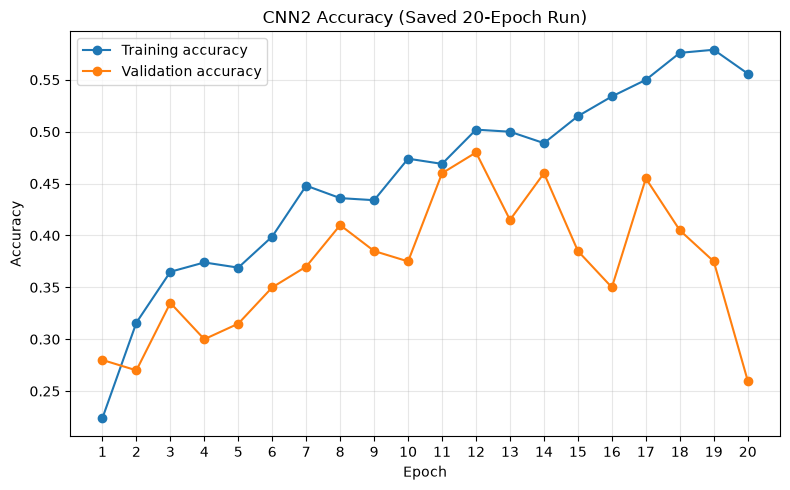

In [23]:
import random

import matplotlib.pyplot as plt
from PIL import Image

# Fall back to the saved run if it predates the accuracy-history tracking above.
if (
    "medium_train_accuracy_history" in globals()
    and medium_train_accuracy_history
    and "medium_val_accuracy_history" in globals()
    and medium_val_accuracy_history
):
    plot_train_accuracy = medium_train_accuracy_history
    plot_val_accuracy = medium_val_accuracy_history
    plot_title = "CNN2 Training and Validation Accuracy"
else:
    plot_train_accuracy = [
        0.224, 0.316, 0.365, 0.374, 0.369, 0.399, 0.448, 0.436, 0.434, 0.474,
        0.469, 0.502, 0.500, 0.489, 0.515, 0.534, 0.550, 0.576, 0.579, 0.556,
    ]
    plot_val_accuracy = [
        0.280, 0.270, 0.335, 0.300, 0.315, 0.350, 0.370, 0.410, 0.385, 0.375,
        0.460, 0.480, 0.415, 0.460, 0.385, 0.350, 0.455, 0.405, 0.375, 0.260,
    ]
    plot_title = "CNN2 Accuracy (Saved 20-Epoch Run)"
    print("Plotting the saved 20-epoch results. Rerun training to plot a new run.")

if len(plot_train_accuracy) != len(plot_val_accuracy):
    raise ValueError("Training and validation accuracy histories have different lengths.")

epochs = range(1, len(plot_train_accuracy) + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, plot_train_accuracy, marker="o", label="Training accuracy")
plt.plot(epochs, plot_val_accuracy, marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(plot_title)
plt.xticks(list(epochs))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Task 1 ViT Model

In [ ]:
# implement the VIT Model Here
import torch
import torch.nn as nn

class ViT(nn.Module):

    def __init__(
        self,
        image_size,           # height and width of the square input image
        patch_size,           # height and width of each square patch
        hidden_dim,           # length of each token's embedding feature vector
        num_heads,            # number of parallel attention heads in each transformer
        mlp_dim,              # size of the hidden layer in each transformer block's FFN
        embedding_dropout,    # dropout probability applied after combining patch/class tokens w/ positional embeddings
        stride=None,          # distance the patch extraction window moves between patches
        num_classes=10,       # number of output categories
        encoder_dropout=0.1,  # dropout probability used by each ecncoder block
        num_layers=4,         # number of transformer encoder blocks
    ):
        super().__init__()

        # stride is different than patch size, only if we want to try overlapping patches
        stride = patch_size if stride is None else stride

        # sanity check data validation
        positive_values = {
            "image_size": image_size,
            "patch_size": patch_size,
            "stride": stride,
            "hidden_dim": hidden_dim,
            "num_heads": num_heads,
            "mlp_dim": mlp_dim,
            "num_classes": num_classes,
            "num_layers": num_layers,
        }
        for name, value in positive_values.items():
            if value <= 0:
                raise ValueError(f"{name} must be positive, got {value}")

        if image_size < patch_size:
            raise ValueError("patch_size cannot exceed image_size")
        if stride > patch_size:
            raise ValueError("stride cannot exceed patch_size because this would skip pixels")
        if (image_size - patch_size) % stride != 0:
            raise ValueError(
                "image_size, patch_size, and stride leave an unused image border"
            )
        if hidden_dim % num_heads != 0:
            raise ValueError(
                f"hidden_dim {hidden_dim} must be divisible by num_heads {num_heads}"
            )
        if not 0 <= encoder_dropout < 1:
            raise ValueError(f"dropout must be in [0, 1), got {encoder_dropout}")
        if not 0 <= embedding_dropout < 1:
            raise ValueError(
                f"embedding_dropout must be in [0, 1), got {embedding_dropout}"
            )

        self.image_size = image_size
        self.patch_size = patch_size
        self.num_classes = num_classes
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        self.num_heads = num_heads
        self.mlp_dim = mlp_dim
        self.stride = stride

        patches_per_side = ((image_size - patch_size) // stride) + 1
        self.num_patches = patches_per_side**2

        # convolutional patch extractor
        self.patch_embed = nn.Conv2d(
            3, hidden_dim, kernel_size=patch_size, stride=stride
        )

        # class token initialization
        self.class_token = nn.Parameter(torch.zeros(1, 1, hidden_dim))

        # learnable positional embedding initialization
        self.pos_embed = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, hidden_dim)
        )
        self.embedding_dropout = nn.Dropout(embedding_dropout)

        # transformer encoder initialization
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim, 
            nhead=num_heads, 
            dim_feedforward=mlp_dim, 
            dropout=encoder_dropout, 
            activation="gelu", 
            batch_first=True, 
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # normalize the final class token representation before classification
        self.norm = nn.LayerNorm(hidden_dim)

        # map the class token representation to one output logit per class
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # create patch embedding from image 
        x = self.patch_embed(x)
        x = x.flatten(2).transpose(1, 2)

        # add class token and positional embeddings w/ dropout
        class_token = self.class_token.expand(x.size(0), -1, -1)
        x = torch.cat([class_token, x], dim=1)
        x = self.embedding_dropout(x + self.pos_embed)

        # pass input through encoder
        x = self.encoder(x)

        # apply layer normal and extract class token
        class_token_output = self.norm(x[:, 0])

        # map the class token representation to one output logit per class
        logits = self.classifier(class_token_output)

        return logits



/Users/jaragao/ECSE-551-A2/.venv/lib/python3.14/site-packages/torch/_subclasses/functional_tensor.py:377: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:82.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


## Shared Dataset Pipeline

Create one reproducible data index and stratified split for both the CNN and ViT. The dataset classes accept transforms but do not define augmentation themselves.

In [ ]:
import csv
import random
from collections import Counter, defaultdict
from dataclasses import dataclass
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


@dataclass(frozen=True)
class LabeledImageRecord:   # records used for training and validation
    image_path: Path        # location of the RGB image
    mask_path: Path         # location of the corresponding object mask
    label_name: str         # human readable class name e.g. bird, cat, etc...
    label_index: int        # numeric class index expected by CrossEntropyLoss


@dataclass(frozen=True)     
class TestImageRecord:      # unlabeled Kaggle test image records
    image_path: Path        # location of the RGB image
    file_name: str          # image file name
    submission_id: int      # numeric ID for Kaggle submission


def load_rival10_records(data_root=Path("./data"), expected_num_classes=10):
    """Load and validate the labeled training index and unlabeled test index"""

    # build the paths to the data
    data_root = Path(data_root)
    train_csv_path = data_root / "train.csv"
    test_csv_path = data_root / "test.csv"
    archive_root = data_root / "archive" / "RIVAL10_Kaggle"
    test_image_root = archive_root / "test" / "test_images"

    # sanity check on paths
    required_paths = [train_csv_path, test_csv_path, archive_root, test_image_root]
    for required_path in required_paths:
        if not required_path.exists():
            raise FileNotFoundError(f"Required dataset path not found: {required_path.resolve()}")

    # open the train csv and read the rows
    with train_csv_path.open(newline="", encoding="utf-8-sig") as file:
        train_rows = list(csv.DictReader(file))
    if not train_rows:
        raise ValueError(f"No training rows found in {train_csv_path}")
    if not {"image_path", "label_name"}.issubset(train_rows[0]):
        raise ValueError("train.csv must contain image_path and label_name columns")

    # extract the unique class names, there should be 10
    class_names = sorted({row["label_name"] for row in train_rows})
    if len(class_names) != expected_num_classes:
        raise ValueError(
            f"Expected {expected_num_classes} classes, found {len(class_names)}: {class_names}"
        )

    # create label-index lookups
    label_to_index = {name: index for index, name in enumerate(class_names)}
    index_to_label = {index: name for name, index in label_to_index.items()}

    labeled_records = []
    seen_train_paths = set()

    # loop through all the labeled rows from train.csv and creates on LabeledImageRecord per row
    for row in train_rows:
        relative_path = Path(row["image_path"])
        if not relative_path.parts or relative_path.parts[0] != "RIVAL10":
            raise ValueError(f"Unexpected training image path: {relative_path}")

        image_path = archive_root.joinpath(*relative_path.parts[1:])
        mask_path = image_path.with_name(
            f"{image_path.stem}_merged_mask{image_path.suffix}"
        )
        if image_path in seen_train_paths:
            raise ValueError(f"Duplicate training image path: {image_path}")
        if not image_path.is_file():
            raise FileNotFoundError(f"Training image not found: {image_path}")
        if not mask_path.is_file():
            raise FileNotFoundError(f"Object mask not found: {mask_path}")

        seen_train_paths.add(image_path)
        label_name = row["label_name"]
        labeled_records.append(
            LabeledImageRecord(
                image_path=image_path,
                mask_path=mask_path,
                label_name=label_name,
                label_index=label_to_index[label_name],
            )
        )

    # open the test csv and read the rows
    with test_csv_path.open(newline="", encoding="utf-8-sig") as file:
        test_rows = list(csv.DictReader(file))
    if not test_rows:
        raise ValueError(f"No test rows found in {test_csv_path}")
    if "id" not in test_rows[0]:
        raise ValueError("test.csv must contain an id column")

    test_records = []
    seen_test_names = set()

    # loop through all the rows from test.csv and creates on TestImageRecord per row
    for row in test_rows:
        file_name = row["id"]
        image_path = test_image_root / file_name
        if file_name in seen_test_names:
            raise ValueError(f"Duplicate test image ID: {file_name}")
        if not image_path.is_file():
            raise FileNotFoundError(f"Test image not found: {image_path}")

        try:
            submission_id = int(Path(file_name).stem)
        except ValueError as error:
            raise ValueError(f"Test filename does not contain a numeric ID: {file_name}") from error

        seen_test_names.add(file_name)
        test_records.append(
            TestImageRecord(
                image_path=image_path,
                file_name=file_name,
                submission_id=submission_id,
            )
        )

    return labeled_records, test_records, label_to_index, index_to_label


def stratified_train_val_split(records, validation_fraction=0.1, seed=42):
    """Make a reproducible split that preserves every class proportion"""

    # sanity check input validation
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction must be strictly between 0 and 1")

    # group all image records according to their class label
    records_by_label = defaultdict(list)
    for record in records:
        records_by_label[record.label_index].append(record)

    # create a random number generator using the passed in seed
    rng = random.Random(seed)
    train_records = []
    validation_records = []

    # retrieves all records for the current class and sorts them by image
    for label_index in sorted(records_by_label):
        class_records = sorted(
            records_by_label[label_index], key=lambda record: str(record.image_path)
        )

        # randomly rearranges the current class’s images
        rng.shuffle(class_records)

        # calculates how many images from this class should enter validation set
        validation_count = round(len(class_records) * validation_fraction)
        # ensures the validation set gets at least one image but never every image from the class
        validation_count = max(1, min(validation_count, len(class_records) - 1))

        # divide the shuffled records for the current class between validation and training
        validation_records.extend(class_records[:validation_count])
        train_records.extend(class_records[validation_count:])

    # randomly shuffle the training and validation set, since images were added class by class
    rng.shuffle(train_records)
    rng.shuffle(validation_records)
    return train_records, validation_records


class RIVAL10Dataset(Dataset):
    """Shared labeled-image dataset for CNN and ViT training or evaluation"""

    def __init__(self, records, transform=None, return_metadata=False):
        self.records = list(records)
        self.transform = transform
        self.return_metadata = return_metadata

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        with Image.open(record.image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image) if self.transform is not None else image.copy()

        if not self.return_metadata:
            return image, record.label_index

        metadata = {
            "image_path": str(record.image_path),
            "mask_path": str(record.mask_path),
            "label_name": record.label_name,
        }
        return image, record.label_index, metadata


class RIVAL10TestDataset(Dataset):
    """Unlabeled test dataset that preserves Kaggle submission IDs."""

    def __init__(self, records, transform=None):
        self.records = list(records)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        with Image.open(record.image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image) if self.transform is not None else image.copy()
        return image, record.submission_id


In [ ]:
# Build the shared index and fixed split used by both models.
DATA_ROOT = Path("./data")
VALIDATION_FRACTION = 0.1
SPLIT_SEED = 42

# load all the records
all_labeled_records, test_records, label_to_index, index_to_label = (
    load_rival10_records(DATA_ROOT)
)

# create the training and validation straitified splits
train_records, validation_records = stratified_train_val_split(
    all_labeled_records,
    validation_fraction=VALIDATION_FRACTION,
    seed=SPLIT_SEED,
)

train_counts = Counter(record.label_name for record in train_records)
validation_counts = Counter(record.label_name for record in validation_records)

print(f"Training images: {len(train_records):,}")
print(f"Validation images: {len(validation_records):,}")
print(f"Test images: {len(test_records):,}")
print("Label mapping:", label_to_index)
print("Training class counts:", dict(sorted(train_counts.items())))
print("Validation class counts:", dict(sorted(validation_counts.items())))


## Shared Image Transformations for Data Augmentation

In [ ]:
import torch
from PIL import Image
from torchvision.transforms import InterpolationMode, v2


def calculate_channel_statistics(records):
    """Calculate RGB mean and standard deviation from training records only"""
    if not records:
        raise ValueError("At least one training record is required")

    to_float_image = v2.Compose(
        [
            v2.ToImage(),
            v2.ToDtype(torch.float64, scale=True),
        ]
    )
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    pixel_count = 0

    for record in records:
        with Image.open(record.image_path) as image:
            image_tensor = to_float_image(image.convert("RGB"))

        channel_sum += image_tensor.sum(dim=(1, 2))
        channel_squared_sum += image_tensor.square().sum(dim=(1, 2))
        pixel_count += image_tensor.shape[1] * image_tensor.shape[2]

    channel_mean = channel_sum / pixel_count
    channel_variance = channel_squared_sum / pixel_count - channel_mean.square()
    channel_std = channel_variance.clamp_min(0).sqrt()

    # we will use these to normalize the inputs making optimization more stable and ensure RGB on similar scales
    return tuple(channel_mean.tolist()), tuple(channel_std.tolist())


def create_transforms(image_size, channel_mean, channel_std):
    """Create shared training and evaluation transforms for the CNN and ViT"""

    # input sanity check
    if not isinstance(image_size, int) or isinstance(image_size, bool):
        raise TypeError("image_size must be an integer")
    if image_size <= 0:
        raise ValueError("image_size must be positive")


    # use torchvision transform api to compose data augmentation transformations for training
    train_transform = v2.Compose(
        [
            # convert PIL image to torchvision tesnor (h, w, c) to (c, h, w)
            v2.ToImage(),

            # perform rnadom resized crops (still preserving original dimensions)
            v2.RandomResizedCrop(
                size=(image_size, image_size),
                scale=(0.8, 1.0),                           # area of the randomly selected crop relative to the complete image
                ratio=(0.9, 1.1),                           # crop’s aspect ratio (w/h)
                interpolation=InterpolationMode.BILINEAR,   # determines the new pixel values by blending nearby source pixels
            ),
            v2.RandomHorizontalFlip(p=0.5), # randomly horizontally flip the image half of the time

            # add random color variation
            v2.ColorJitter(
                brightness=0.2,  
                contrast=0.2,
                saturation=0.2,
                hue=0.05,
            ),

            # typecast from integers [0, 255] to floats [0.0, 1.0] needed for NNs
            v2.ToDtype(torch.float32, scale=True),

            # normalizes every pixel channel using fixed statistics calculated from the training dataset
            v2.Normalize(
                mean=channel_mean,
                std=channel_std,
            ),
        ]
    )

    # for evaluation we don't do random transformations but some light deterministic pre-processing
    evaluation_transform = v2.Compose(
        [
            # convert PIL image to torchvision tensor (h, w, c) to (c, h, w)
            v2.ToImage(),

            # deterministically resize the image to the dimensions expected by the model
            v2.Resize(
                size=(image_size, image_size),
                interpolation=InterpolationMode.BILINEAR,
                antialias=True,
            ),

            # typecast from integers [0, 255] to floats [0.0, 1.0] needed for NNs
            v2.ToDtype(torch.float32, scale=True),

            # normalize every pixel channel using fixed training-dataset statistics
            v2.Normalize(
                mean=channel_mean,
                std=channel_std,
            ),
        ]
    )

    return train_transform, evaluation_transform


In [ ]:
# Cache normalization statistics because calculating them reads every training image.
import json
import math
from tempfile import NamedTemporaryFile


def load_cached_channel_statistics(cache_path, expected_metadata):
    """Return validated cached mean/std values, or None for a stale cache."""
    cache_path = Path(cache_path)
    if not cache_path.is_file():
        return None

    try:
        payload = json.loads(cache_path.read_text(encoding="utf-8"))
        if payload.get("metadata") != expected_metadata:
            print("Ignoring stale channel-statistics cache:", cache_path)
            return None

        channel_mean = tuple(float(value) for value in payload["channel_mean"])
        channel_std = tuple(float(value) for value in payload["channel_std"])
        if len(channel_mean) != 3 or len(channel_std) != 3:
            raise ValueError("Channel statistics must contain three values")
        if not all(math.isfinite(value) for value in channel_mean + channel_std):
            raise ValueError("Channel statistics must be finite")
        if not all(value > 0 for value in channel_std):
            raise ValueError("Channel standard deviations must be positive")
    except (OSError, TypeError, ValueError, KeyError) as error:
        print(f"Ignoring invalid channel-statistics cache {cache_path}: {error}")
        return None

    return channel_mean, channel_std


def save_channel_statistics(cache_path, metadata, channel_mean, channel_std):
    """Atomically save reusable channel statistics and their split metadata."""
    cache_path = Path(cache_path)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "metadata": metadata,
        "channel_mean": list(channel_mean),
        "channel_std": list(channel_std),
    }

    with NamedTemporaryFile(
        mode="w",
        encoding="utf-8",
        dir=cache_path.parent,
        delete=False,
    ) as temporary_file:
        json.dump(payload, temporary_file, indent=2, sort_keys=True)
        temporary_path = Path(temporary_file.name)

    try:
        temporary_path.replace(cache_path)
    finally:
        temporary_path.unlink(missing_ok=True)


STATISTICS_CACHE_VERSION = 1
statistics_cache_path = CHECKPOINT_ROOT / "dataset_statistics.json"
statistics_metadata = {
    "cache_version": STATISTICS_CACHE_VERSION,
    "split_seed": SPLIT_SEED,
    "validation_fraction": VALIDATION_FRACTION,
    "training_image_count": len(train_records),
    "label_to_index": dict(sorted(label_to_index.items())),
}

cached_statistics = load_cached_channel_statistics(
    statistics_cache_path, statistics_metadata
)
if cached_statistics is None:
    print("Calculating channel statistics from the training split...")
    rival10_channel_mean, rival10_channel_std = calculate_channel_statistics(
        train_records
    )
    save_channel_statistics(
        statistics_cache_path,
        statistics_metadata,
        rival10_channel_mean,
        rival10_channel_std,
    )
    print("Saved channel statistics:", statistics_cache_path)
else:
    rival10_channel_mean, rival10_channel_std = cached_statistics
    print("Loaded cached channel statistics:", statistics_cache_path)

print("Training channel mean:", rival10_channel_mean)
print("Training channel standard deviation:", rival10_channel_std)


## Shared Datasets and DataLoaders

Apply the shared transformations and create reproducible DataLoaders for training, validation, and Kaggle test inference.

In [ ]:
import torch
from torch.utils.data import DataLoader


def create_dataloaders(
    train_records,
    validation_records,
    test_records,
    image_size,
    channel_mean,
    channel_std,
    batch_size=32,
    num_workers=0,
    seed=42,
):
    """Create shared training, validation, and test DataLoaders"""

    # sanity check the DataLoader settings
    if not isinstance(batch_size, int) or isinstance(batch_size, bool):
        raise TypeError("batch_size must be an integer")
    if batch_size <= 0:
        raise ValueError("batch_size must be positive")
    if not isinstance(num_workers, int) or isinstance(num_workers, bool):
        raise TypeError("num_workers must be an integer")
    if num_workers < 0:
        raise ValueError("num_workers cannot be negative")
    if not isinstance(seed, int) or isinstance(seed, bool):
        raise TypeError("seed must be an integer")
    if not train_records or not validation_records or not test_records:
        raise ValueError("Training, validation, and test records cannot be empty")

    # create random training transforms and deterministic evaluation transforms
    train_transform, evaluation_transform = create_transforms(
        image_size=image_size,
        channel_mean=channel_mean,
        channel_std=channel_std,
    )

    # apply the correct transform pipeline to each dataset split
    train_dataset = RIVAL10Dataset(train_records, transform=train_transform)
    validation_dataset = RIVAL10Dataset(
        validation_records, transform=evaluation_transform
    )
    test_dataset = RIVAL10TestDataset(test_records, transform=evaluation_transform)

    # seed the training sampler and worker processes for reproducible loading
    loader_generator = torch.Generator().manual_seed(seed)
    # checks whether an NVIDIA CUDA GPU is available
    use_pin_memory = torch.cuda.is_available()
    keep_workers_alive = num_workers > 0

    # shuffle training images every epoch but preserve validation and test order
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,                 # controls how many additional CPU processes prepare data in the background
        pin_memory=use_pin_memory,
        persistent_workers=keep_workers_alive,   # reduces the startup delay between epochs
        generator=loader_generator,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=use_pin_memory,
        persistent_workers=keep_workers_alive,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=use_pin_memory,
        persistent_workers=keep_workers_alive,
    )

    return train_loader, validation_loader, test_loader


def verify_dataloader_batch(data_loader, split_name, image_size, num_classes=None):
    """Validate the shape, type, and values of one DataLoader batch"""

    # this function performs a safety check before starting a long training run

    # retrieve one batch from the requested split
    images, targets = next(iter(data_loader))

    # ensure the model will receive a batch of RGB images at the expected size
    expected_image_shape = (3, image_size, image_size)
    if images.ndim != 4 or tuple(images.shape[1:]) != expected_image_shape:
        raise ValueError(
            f"{split_name} images have shape {tuple(images.shape)}; "
            f"expected (batch_size, {expected_image_shape})"
        )
    if images.dtype != torch.float32:
        raise TypeError(f"{split_name} images must use torch.float32")
    if not torch.isfinite(images).all():
        raise ValueError(f"{split_name} images contain NaN or infinity")

    # ensure each image has exactly one integer label or submission ID
    if targets.ndim != 1 or targets.shape[0] != images.shape[0]:
        raise ValueError(f"{split_name} targets do not match the image batch")
    if targets.dtype != torch.int64:
        raise TypeError(f"{split_name} targets must use torch.int64")

    # confirm labeled splits only contain valid class indices
    if num_classes is not None:
        if targets.min().item() < 0 or targets.max().item() >= num_classes:
            raise ValueError(f"{split_name} contains an invalid class index")

    print(
        f"{split_name}: images {tuple(images.shape)}, targets {tuple(targets.shape)}, "
        f"range [{images.min().item():.3f}, {images.max().item():.3f}]"
    )
    return images, targets


In [ ]:
# configure the shared loaders for full-resolution model development
SHARED_IMAGE_SIZE = 224
SHARED_BATCH_SIZE = 32
SHARED_NUM_WORKERS = 2 if IN_COLAB else 0
DATALOADER_SEED = 42

# create loaders that both the CNN and ViT can use
train_loader, validation_loader, test_loader = create_dataloaders(
    train_records=train_records,
    validation_records=validation_records,
    test_records=test_records,
    image_size=SHARED_IMAGE_SIZE,
    channel_mean=rival10_channel_mean,
    channel_std=rival10_channel_std,
    batch_size=SHARED_BATCH_SIZE,
    num_workers=SHARED_NUM_WORKERS,
    seed=DATALOADER_SEED,
)

# verify one batch from every split before using the loaders for training or inference
train_images, train_labels = verify_dataloader_batch(
    train_loader, "Training", SHARED_IMAGE_SIZE, num_classes=len(label_to_index)
)
validation_images, validation_labels = verify_dataloader_batch(
    validation_loader,
    "Validation",
    SHARED_IMAGE_SIZE,
    num_classes=len(label_to_index),
)
test_images, test_submission_ids = verify_dataloader_batch(
    test_loader, "Test", SHARED_IMAGE_SIZE
)

# confirm that repeated evaluation access produces exactly the same image tensor
first_evaluation_image, _ = validation_loader.dataset[0]
second_evaluation_image, _ = validation_loader.dataset[0]
if not torch.equal(first_evaluation_image, second_evaluation_image):
    raise ValueError("Validation preprocessing must be deterministic")
print("Validation preprocessing is deterministic.")


### Training Augmentation Preview

Reverse normalization for display and visually confirm that the random training transformations preserve recognizable images.

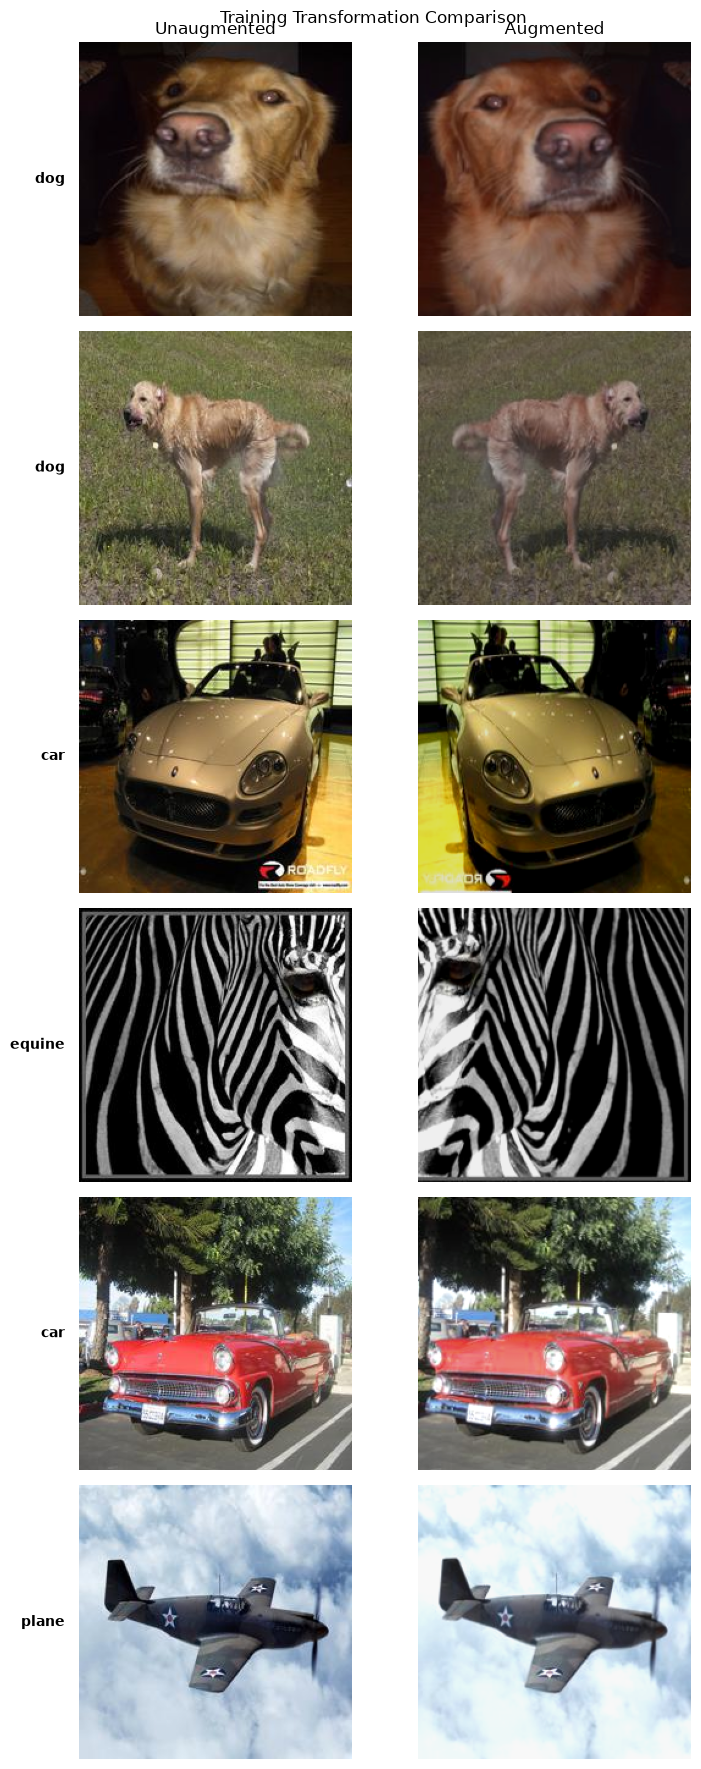

In [11]:
import matplotlib.pyplot as plt


def reverse_normalization(image, channel_mean, channel_std):
    """Convert a normalized image back to the display range [0, 1]"""
    mean = torch.tensor(channel_mean, dtype=image.dtype).view(3, 1, 1)
    std = torch.tensor(channel_std, dtype=image.dtype).view(3, 1, 1)
    return (image * std + mean).clamp(0, 1)


# reproducibly select several training records for a side-by-side comparison
preview_count = min(6, len(train_records))
preview_rng = random.Random(DATALOADER_SEED)
preview_records = preview_rng.sample(train_records, preview_count)

# reuse the exact transform pipelines assigned to the shared datasets
training_transform = train_loader.dataset.transform
evaluation_transform = validation_loader.dataset.transform

# show deterministic preprocessing and random augmentation of each source image
figure, axes = plt.subplots(
    preview_count, 2, figsize=(8, 3 * preview_count), squeeze=False
)
for row_index, record in enumerate(preview_records):
    with Image.open(record.image_path) as image:
        image = image.convert("RGB")
        unaugmented_image = evaluation_transform(image.copy())
        augmented_image = training_transform(image.copy())

    unaugmented_image = reverse_normalization(
        unaugmented_image, rival10_channel_mean, rival10_channel_std
    )
    augmented_image = reverse_normalization(
        augmented_image, rival10_channel_mean, rival10_channel_std
    )

    axes[row_index, 0].imshow(unaugmented_image.permute(1, 2, 0).cpu())
    axes[row_index, 1].imshow(augmented_image.permute(1, 2, 0).cpu())
    axes[row_index, 0].text(
        -0.05,
        0.5,
        record.label_name,
        transform=axes[row_index, 0].transAxes,
        horizontalalignment="right",
        verticalalignment="center",
        fontweight="bold",
    )
    axes[row_index, 0].axis("off")
    axes[row_index, 1].axis("off")

axes[0, 0].set_title("Unaugmented")
axes[0, 1].set_title("Augmented")
figure.suptitle("Training Transformation Comparison")
figure.tight_layout()
plt.show()


## Shared Training Setup

Configure reproducibility and automatically select CUDA, Apple MPS, or CPU for both models.

In [ ]:
import random

import numpy as np
import torch


def set_random_seed(seed=42):
    """Seed the random-number generators used by the training pipeline"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # seed every CUDA device when training on a GPU
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def select_device():
    """Select CUDA, Apple MPS, or CPU in that order"""

    # this will be true when training on collab with the t4
    if torch.cuda.is_available():
        return torch.device("cuda")

    # lets M-series macs training with new GPU on Apple Silicon for local testing [smoke testing]
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")

    # if not just use cpu [smoke testing]
    return torch.device("cpu")


# use the same seed for reproducible CNN and ViT experiments
TRAINING_SEED = 42
set_random_seed(TRAINING_SEED)

# use CUDA in Colab, Apple MPS when available locally, or otherwise the CPU
device = select_device()
print("Training device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


## Shared Training Functions

Use the same training, evaluation, and checkpoint workflow for both models while instantiating each CNN and ViT experiment with its own architecture and hyperparameters.

In [ ]:
def train_one_epoch(model, data_loader, optimizer, criterion, device):
    """Train for one epoch with the supplied optimizer and loss function.

    The criterion must accept logits and class indices and return a scalar
    loss averaged over the images in the batch.
    """
    # enable training behavior for dropout and batch normalization
    model.train()

    # initialize totals for loss, correct predictions, and images seen
    total_loss = 0.0
    total_correct = 0
    total_images = 0

    for images, labels in data_loader:
        # move the images and labels to the selected device
        images = images.to(device)
        labels = labels.to(device)

        # clear gradients by setting them to none before each batch
        optimizer.zero_grad(set_to_none=True)

        # run the forward pass in standard precision to get class logits
        logits = model(images)

        # compute the batch loss from logits and class indices using the criterion
        loss = criterion(logits, labels)

        # backpropagate the loss to compute gradients
        loss.backward()

        # take one optimizer step per batch to update the model parameters
        optimizer.step()

        # use the same logits to count correct predictions and images seen
        batch_size = labels.size(0)
        predictions = logits.detach().argmax(dim=1)
        total_correct += (predictions == labels).sum().item()
        total_images += batch_size

        # multiply the mean batch loss by its image count so a short final batch
        # contributes in proportion to the number of images it contains
        total_loss += loss.item() * batch_size

    # divide by the number of images seen to return mean loss and accuracy as floats
    if total_images == 0:
        raise ValueError("Training loader yielded no images")
    return {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
    }


In [ ]:
def evaluate(model, data_loader, criterion, device):
    """Evaluate a model without updating its parameters.

    The criterion must accept logits and class indices and return a scalar
    loss averaged over the images in the batch.
    """
    # set the model to evaluation mode for dropout and batch normalization
    model.eval()

    # initialize totals for loss, correct predictions, and images seen
    total_loss = 0.0
    total_correct = 0
    total_images = 0

    # disable gradient tracking for the evaluation pass
    with torch.inference_mode():

        for images, labels in data_loader:
            # move the images and labels to the selected device
            images = images.to(device)
            labels = labels.to(device)

            # run the forward pass to get class logits
            logits = model(images)

            # compute the batch loss using the criterion and count correct predictions
            loss = criterion(logits, labels)
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()

            # weight each mean batch loss by image count so a short final batch
            # contributes in proportion to the number of images it contains
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_images += batch_size

    # return the mean loss and accuracy across all images seen
    if total_images == 0:
        raise ValueError("Evaluation loader yielded no images")
    return {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
    }


In [ ]:
def fit(
    model,
    train_loader,
    validation_loader,
    optimizer,
    criterion,
    device,
    epochs,
    scheduler=None,
    best_checkpoint_path=None,
    *,
    model_config=None,
    label_to_index=None,
    latest_checkpoint_path=None,
    resume_from=None,
):
    """Return per-epoch metrics and the one-based best epoch.

    If supplied, the scheduler must use the same optimizer and step once per
    epoch. ReduceLROnPlateau receives validation loss and should use min mode.
    The model in memory retains the final epoch weights.
    When resuming, epochs is the total target and the caller should reuse the
    original best checkpoint path and experiment configuration.
    """
    # initialize the epoch history and track the best validation result
    if epochs < 1:
        raise ValueError("epochs must be positive")
    if best_checkpoint_path is not None:
        best_path = Path(best_checkpoint_path).resolve()
        for recovery_path in (latest_checkpoint_path, resume_from):
            if recovery_path is not None and Path(recovery_path).resolve() == best_path:
                raise ValueError("Best and recovery checkpoints must use different paths")
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": [],
    }
    best_epoch = None
    best_result = None
    start_epoch = 1

    # restore the completed epochs before continuing a run
    if resume_from is not None:
        start_epoch, history, best_epoch, best_result = restore_training_state(
            resume_from, model, optimizer, scheduler, device
        )
        if start_epoch > epochs + 1:
            raise ValueError("epochs cannot be less than the number already completed")

    # for each epoch, train on the training loader and evaluate on the validation loader
    for epoch in range(start_epoch, epochs + 1):
        train_metrics = train_one_epoch(model, train_loader, optimizer, criterion, device)
        validation_metrics = evaluate(model, validation_loader, criterion, device)

        # record the training and validation metrics and display epoch progress
        history["train_loss"].append(train_metrics["loss"])
        history["train_accuracy"].append(train_metrics["accuracy"])
        history["validation_loss"].append(validation_metrics["loss"])
        history["validation_accuracy"].append(validation_metrics["accuracy"])
        print(
            f"epoch {epoch}/{epochs} | "
            f"train loss {train_metrics['loss']:.4f}, accuracy {train_metrics['accuracy']:.4f} | "
            f"validation loss {validation_metrics['loss']:.4f}, "
            f"accuracy {validation_metrics['accuracy']:.4f}"
        )

        # step an optional epoch-based scheduler or pass validation loss to reduce on plateau
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(validation_metrics["loss"])
        elif scheduler is not None:
            scheduler.step()

        # pick the highest validation accuracy and break ties with lower validation loss
        result = (validation_metrics["accuracy"], -validation_metrics["loss"])
        if best_result is None or result > best_result:
            best_result = result
            best_epoch = epoch

            # save a checkpoint when a new best epoch is found and a path was supplied
            if best_checkpoint_path is not None:
                save_checkpoint(
                    best_checkpoint_path, model, optimizer, epoch, history, model_config,
                    label_to_index, scheduler=scheduler,
                )

        # when a latest checkpoint path is supplied, save the current state after every epoch
        if latest_checkpoint_path is not None:
            save_checkpoint(
                latest_checkpoint_path, model, optimizer, epoch, history, model_config,
                label_to_index, scheduler=scheduler,
            )

    # return the run history and the best validation result
    history["best_epoch"] = best_epoch
    history["best_validation_accuracy"] = best_result[0]
    history["best_validation_loss"] = -best_result[1]
    return history


In [ ]:
def save_checkpoint(
    checkpoint_path,
    model,
    optimizer,
    epoch,
    history,
    model_config,
    label_to_index,
    *,
    scheduler=None,
):
    """Save the best epoch's model state, training state, and metadata."""
    from tempfile import NamedTemporaryFile

    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "history": history,
        "model_config": model_config,
        "label_to_index": label_to_index,
    }

    # finish writing the new checkpoint before replacing the previous best
    with NamedTemporaryFile(dir=checkpoint_path.parent, delete=False) as temporary_file:
        temporary_path = Path(temporary_file.name)
    try:
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(checkpoint_path)
    finally:
        temporary_path.unlink(missing_ok=True)


In [ ]:
def load_checkpoint(checkpoint_path, model, optimizer=None, device="cpu"):
    """Restore the supplied model and return the checkpoint dictionary.

    The model must match the saved architecture. If restoring an optimizer,
    place the model on device before constructing the matching optimizer.
    """
    # load tensors onto the requested device regardless of where they were saved
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)

    # restore weights into the supplied model and put it on the requested device
    model.to(device)
    model.load_state_dict(checkpoint["model_state_dict"])

    # restore optimizer state only when the caller supplies an optimizer
    if optimizer is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    # return the checkpoint so the caller can inspect the saved epoch and history
    return checkpoint


In [ ]:
def restore_training_state(latest_checkpoint_path, model, optimizer, scheduler=None, device="cpu"):
    """Restore training state from the latest completed epoch."""
    # load the latest checkpoint for this experiment and restore model and optimizer state
    checkpoint = load_checkpoint(latest_checkpoint_path, model, optimizer, device)

    # restore the scheduler state when the run used a scheduler
    scheduler_state = checkpoint["scheduler_state_dict"]
    if (scheduler is None) != (scheduler_state is None):
        raise ValueError("Resume with the same scheduler setup as the original run")
    if scheduler is not None:
        scheduler.load_state_dict(scheduler_state)

    # recover the metric history and use it to find the best validation result so far
    history = checkpoint["history"]
    completed_epochs = checkpoint["epoch"]
    epoch_results = list(zip(
        history["validation_accuracy"],
        (-loss for loss in history["validation_loss"]),
        strict=True,
    ))
    if not epoch_results or len(epoch_results) != completed_epochs:
        raise ValueError("Checkpoint epoch does not match its validation history")
    best_epoch, best_result = max(
        enumerate(epoch_results, start=1), key=lambda entry: entry[1]
    )

    # return the history, best result, and next epoch for fit to continue the run
    return completed_epochs + 1, history, best_epoch, best_result


## CNN Training Experiments

Train fresh CNN2 models with candidate hyperparameter configurations and select the best checkpoint using validation performance.

In [ ]:
# Keep the initial sweep small and controlled: vary one setting at a time.
# Batch size (32) and image size (224) stay fixed in the shared DataLoaders.
RUN_CNN_EXPERIMENTS = False
RESUME_CNN_EXPERIMENTS = False

CNN_EXPERIMENT_CONFIGS = [
    {
        "name": "baseline",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "dropout": 0.3,
        "epochs": 20,
    },
    {
        "name": "lower_learning_rate",
        "learning_rate": 3e-4,
        "weight_decay": 1e-4,
        "dropout": 0.3,
        "epochs": 20,
    },
    {
        "name": "more_dropout",
        "learning_rate": 1e-3,
        "weight_decay": 1e-4,
        "dropout": 0.5,
        "epochs": 20,
    },
    {
        "name": "more_weight_decay",
        "learning_rate": 1e-3,
        "weight_decay": 1e-3,
        "dropout": 0.3,
        "epochs": 20,
    },
]


def run_cnn_experiments(
    experiment_configs, train_loader, validation_loader, device, *,
    checkpoint_dir=CNN_CHECKPOINT_DIR, resume=False,
):
    """Train one fresh CNN2 per configuration and record its best validation result.

    `fit` must return per-epoch lists named train_loss, train_accuracy,
    validation_loss, and validation_accuracy, and save its best-validation
    checkpoint to the supplied best_checkpoint_path.
    Enable resume only with checkpoints from the same configurations and data split.
    """
    import math
    from pathlib import Path

    if not isinstance(experiment_configs, (list, tuple)) or not experiment_configs:
        raise ValueError("At least one CNN experiment configuration is required")
    if not label_to_index:
        raise ValueError("label_to_index must be populated before running experiments")

    required_keys = {"name", "learning_rate", "weight_decay", "dropout", "epochs"}
    names = set()
    for config in experiment_configs:
        if not isinstance(config, dict):
            raise TypeError("Each CNN experiment configuration must be a dictionary")
        missing_keys = required_keys.difference(config)
        if missing_keys:
            raise ValueError(
                f"CNN experiment configuration is missing: {sorted(missing_keys)}"
            )

        name = config["name"]
        if (
            not isinstance(name, str)
            or not name
            or not name.replace("_", "").isalnum()
        ):
            raise ValueError("Experiment names must contain only letters, digits, or underscores")
        if name in names:
            raise ValueError(f"Duplicate CNN experiment name: {name}")
        names.add(name)

        for key in ("learning_rate", "weight_decay", "dropout"):
            value = config[key]
            if isinstance(value, bool) or not isinstance(value, (int, float)):
                raise TypeError(f"{key} must be a number for {name}")
            if not math.isfinite(value):
                raise ValueError(f"{key} must be finite for {name}")
        if config["learning_rate"] <= 0:
            raise ValueError(f"learning_rate must be positive for {name}")
        if config["weight_decay"] < 0:
            raise ValueError(f"weight_decay cannot be negative for {name}")
        if not 0 <= config["dropout"] < 1:
            raise ValueError(f"dropout must be in [0, 1) for {name}")
        if (
            isinstance(config["epochs"], bool)
            or not isinstance(config["epochs"], int)
            or config["epochs"] <= 0
        ):
            raise ValueError(f"epochs must be a positive integer for {name}")

    checkpoint_dir = Path(checkpoint_dir)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    # Reset the sampler generator too, so each run sees the same shuffled order.
    loader_generator = getattr(train_loader, "generator", None)
    initial_generator_state = (
        loader_generator.get_state() if loader_generator is not None else None
    )

    results = []
    for config in experiment_configs:
        name = config["name"]
        set_random_seed(TRAINING_SEED)
        if loader_generator is not None:
            loader_generator.set_state(initial_generator_state)

        model_config = {
            "num_classes": len(label_to_index),
            "dropout": config["dropout"],
        }
        model = CNN2(**model_config).to(device)
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=config["learning_rate"],
            weight_decay=config["weight_decay"],
        )
        best_path = checkpoint_dir / f"cnn2_{name}_best.pt"
        latest_path = checkpoint_dir / f"cnn2_{name}_latest.pt"
        resume_from = latest_path if resume and latest_path.is_file() else None
        if resume_from is not None and not best_path.is_file():
            raise FileNotFoundError(
                f"Keep the best checkpoint with the latest checkpoint: {best_path}"
            )

        history = fit(
            model=model,
            train_loader=train_loader,
            validation_loader=validation_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=device,
            epochs=config["epochs"],
            scheduler=None,
            best_checkpoint_path=best_path,
            model_config=model_config,
            label_to_index=label_to_index,
            latest_checkpoint_path=latest_path,
            resume_from=resume_from,
        )

        history_keys = (
            "train_loss",
            "train_accuracy",
            "validation_loss",
            "validation_accuracy",
        )
        if not isinstance(history, dict):
            raise TypeError("fit must return a history dictionary")
        if any(key not in history for key in history_keys):
            raise KeyError("fit history must contain: " + ", ".join(history_keys))
        if any(not history[key] for key in history_keys):
            raise ValueError("fit returned an empty per-epoch history")
        if len({len(history[key]) for key in history_keys}) != 1:
            raise ValueError("fit history metrics must have matching epoch counts")
        if not best_path.is_file():
            raise FileNotFoundError(
                f"fit did not save the best-validation checkpoint: {best_path}"
            )
        if not latest_path.is_file():
            raise FileNotFoundError(
                f"fit did not save the latest recovery checkpoint: {latest_path}"
            )

        validation_losses = history["validation_loss"]
        validation_accuracies = history["validation_accuracy"]
        best_index = max(
            range(len(validation_accuracies)),
            key=lambda index: (
                float(validation_accuracies[index]),
                -float(validation_losses[index]),
            ),
        )
        metrics = {
            "best_epoch": best_index + 1,
            "best_validation_accuracy": float(validation_accuracies[best_index]),
            "best_validation_loss": float(validation_losses[best_index]),
        }
        results.append(
            {
                "name": name,
                "model_class": "CNN2",
                "config": dict(config),
                "model_config": model_config,
                "history": history,
                "metrics": metrics,
                "checkpoint_path": str(best_path),
                "latest_checkpoint_path": str(latest_path),
            }
        )
        print(
            f"{name}: best epoch {metrics['best_epoch']}, "
            f"validation accuracy {metrics['best_validation_accuracy']:.4f}, "
            f"validation loss {metrics['best_validation_loss']:.4f}"
        )

    return results


if RUN_CNN_EXPERIMENTS:
    cnn_experiment_results = run_cnn_experiments(
        CNN_EXPERIMENT_CONFIGS, train_loader, validation_loader, device,
        checkpoint_dir=CNN_CHECKPOINT_DIR, resume=RESUME_CNN_EXPERIMENTS,
    )


## ViT Training Experiments

Train fresh Vision Transformers with candidate hyperparameter configurations and select the best checkpoint using validation performance.

In [ ]:
# enable only when ready to run the full vit sweep
RUN_VIT_EXPERIMENTS = False
RESUME_VIT_EXPERIMENTS = False

# change one setting at a time from the baseline
VIT_BASELINE = {"name": "baseline", "patch_size": 16, "learning_rate": 3e-4, "epochs": 20}
VIT_EXPERIMENT_CONFIGS = [
    VIT_BASELINE,
    {**VIT_BASELINE, "name": "coarser_patches", "patch_size": 32},
    {**VIT_BASELINE, "name": "higher_learning_rate", "learning_rate": 1e-3},
]


def run_vit_experiments(
    experiment_configs, train_loader, validation_loader, device, *,
    checkpoint_dir=VIT_CHECKPOINT_DIR, resume=False,
):
    """Run the ViT sweep and return one CNN-compatible result per configuration.

    Enable resume only with checkpoints from the same configurations and data split.
    Use a persistent checkpoint directory when running on a rented GPU.
    """
    checkpoint_dir = Path(checkpoint_dir)
    if not experiment_configs:
        raise ValueError("At least one ViT configuration is required")
    names = [config["name"] for config in experiment_configs]
    if any(not name.replace("_", "").isalnum() for name in names) or len(set(names)) != len(names):
        raise ValueError("ViT experiment names must be unique and use letters, digits, or underscores")

    # capture the loader shuffle state so fresh runs see the same batch order
    loader_generator = getattr(train_loader, "generator", None)
    initial_generator_state = loader_generator.get_state() if loader_generator is not None else None

    results = []
    for config in experiment_configs:
        name = config["name"]

        # reset the model seed and loader shuffle before each experiment
        set_random_seed(TRAINING_SEED)
        if loader_generator is not None:
            loader_generator.set_state(initial_generator_state)

        # build a fresh vit with the shared architecture and the selected patch size
        model_config = {
            "image_size": SHARED_IMAGE_SIZE,
            "patch_size": config["patch_size"],
            "hidden_dim": 128,
            "num_heads": 4,
            "mlp_dim": 256,
            "embedding_dropout": 0.1,
            "encoder_dropout": 0.1,
            "num_layers": 4,
            "num_classes": len(label_to_index),
        }
        model = ViT(**model_config).to(device)

        # use plain cross-entropy and keep adamw's default weight decay
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"])

        # give each run separate best and latest checkpoint paths
        best_path = checkpoint_dir / f"vit_{name}_best.pt"
        latest_path = checkpoint_dir / f"vit_{name}_latest.pt"
        resume_from = latest_path if resume and latest_path.is_file() else None
        if resume_from is not None and not best_path.is_file():
            raise FileNotFoundError(f"Keep the best checkpoint with the latest checkpoint: {best_path}")

        # use the fixed split and keep the learning rate constant throughout the run
        history = fit(
            model, train_loader, validation_loader, optimizer, criterion, device,
            epochs=config["epochs"],
            best_checkpoint_path=best_path,
            model_config=model_config,
            label_to_index=label_to_index,
            latest_checkpoint_path=latest_path,
            resume_from=resume_from,
        )

        # record the winning epoch and metrics reported by fit
        metrics = {
            key: history[key]
            for key in ("best_epoch", "best_validation_accuracy", "best_validation_loss")
        }
        results.append({
            "name": name,
            "config": dict(config),
            "model_config": model_config,
            "history": history,
            "metrics": metrics,
            "checkpoint_path": str(best_path),
            "latest_checkpoint_path": str(latest_path),
        })

    # return every experiment result for comparison
    return results


if RUN_VIT_EXPERIMENTS:
    vit_experiment_results = run_vit_experiments(
        VIT_EXPERIMENT_CONFIGS, train_loader, validation_loader, device,
        checkpoint_dir=VIT_CHECKPOINT_DIR, resume=RESUME_VIT_EXPERIMENTS,
    )


## Experiment Results and Model Selection

Compare completed runs from any model family and select the best checkpoint using validation accuracy, with validation loss as a tie-breaker. Model selection uses validation data only.

In [ ]:
import math


def select_best_experiment(experiment_results):
    """Return the best completed run by validation accuracy, then loss."""
    if not isinstance(experiment_results, (list, tuple)) or not experiment_results:
        raise ValueError("experiment_results must be a non-empty list or tuple")

    ranked_results = []
    for position, result in enumerate(experiment_results):
        if not isinstance(result, dict):
            raise TypeError("Each experiment result must be a dictionary")

        metrics = result.get("metrics", {})
        history = result.get("history", {})
        if not isinstance(metrics, dict) or not isinstance(history, dict):
            raise TypeError("Experiment metrics and history must be dictionaries")

        accuracy = metrics.get("best_validation_accuracy")
        loss = metrics.get("best_validation_loss")
        if accuracy is None or loss is None:
            accuracies = history.get("validation_accuracy", [])
            losses = history.get("validation_loss", [])
            if not accuracies or len(accuracies) != len(losses):
                raise ValueError(
                    f"Experiment {result.get('name', position)!r} has no complete validation metrics"
                )
            best_epoch = max(
                range(len(accuracies)),
                key=lambda epoch: (float(accuracies[epoch]), -float(losses[epoch])),
            )
            accuracy = accuracies[best_epoch]
            loss = losses[best_epoch]

        if isinstance(accuracy, bool) or isinstance(loss, bool):
            raise TypeError("Validation accuracy and loss must be numeric")
        try:
            accuracy = float(accuracy)
            loss = float(loss)
        except (TypeError, ValueError) as error:
            raise TypeError("Validation accuracy and loss must be numeric") from error
        if not math.isfinite(accuracy) or not math.isfinite(loss):
            raise ValueError("Validation metrics must be finite")
        if not 0.0 <= accuracy <= 1.0:
            raise ValueError("Validation accuracy must be between 0 and 1")

        ranked_results.append((accuracy, -loss, -position, result))

    best_accuracy, negative_loss, _, best_result = max(
        ranked_results, key=lambda item: item[:3]
    )
    print(
        f"Selected {best_result.get('name', 'unnamed experiment')}: "
        f"validation accuracy {best_accuracy:.4f}, validation loss {-negative_loss:.4f}"
    )
    return best_result


## Final Validation Evaluation

Restore a selected checkpoint with its supplied model factory, then report overall and per-class metrics on the fixed validation split. All evaluation helpers accept any model that returns class logits.

In [ ]:
import torch


def collect_validation_predictions(model, data_loader, device):
    """Return CPU labels, predictions, and probabilities in loader order."""
    model = model.to(device)
    model.eval()
    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.inference_mode():
        for batch in data_loader:
            if not isinstance(batch, (tuple, list)) or len(batch) < 2:
                raise ValueError("Each validation batch must contain images and labels")
            images, labels = batch[0], batch[1]
            images = images.to(device)
            labels = torch.as_tensor(labels)
            if labels.ndim != 1 or labels.shape[0] != images.shape[0]:
                raise ValueError("Validation labels must match the image batch")

            logits = model(images)
            if not isinstance(logits, torch.Tensor) or logits.ndim != 2:
                raise TypeError("The model must return a (batch_size, num_classes) logits tensor")
            if logits.shape[0] != images.shape[0] or logits.shape[1] == 0:
                raise ValueError("Model logits do not match the validation batch")
            if not torch.isfinite(logits).all():
                raise ValueError("Model logits contain NaN or infinity")

            probabilities = torch.softmax(logits, dim=1)
            all_labels.append(labels.detach().to(device="cpu", dtype=torch.int64))
            all_predictions.append(logits.argmax(dim=1).detach().cpu())
            all_probabilities.append(probabilities.detach().cpu())

    if not all_labels:
        raise ValueError("The validation DataLoader produced no batches")
    return (
        torch.cat(all_labels),
        torch.cat(all_predictions),
        torch.cat(all_probabilities),
    )


def calculate_classification_metrics(labels, predictions, class_names):
    """Calculate overall and per-class metrics from integer class indices."""
    labels = torch.as_tensor(labels).detach().cpu()
    predictions = torch.as_tensor(predictions).detach().cpu()
    class_names = list(class_names)
    if not class_names:
        raise ValueError("class_names cannot be empty")
    if labels.ndim != 1 or predictions.ndim != 1 or labels.numel() != predictions.numel():
        raise ValueError("labels and predictions must be equally sized one-dimensional arrays")
    if labels.numel() == 0:
        raise ValueError("Cannot calculate metrics for an empty validation set")
    if labels.dtype.is_floating_point or predictions.dtype.is_floating_point:
        raise TypeError("labels and predictions must contain integer class indices")
    labels = labels.to(torch.int64)
    predictions = predictions.to(torch.int64)
    num_classes = len(class_names)
    if (
        labels.min().item() < 0 or predictions.min().item() < 0
        or labels.max().item() >= num_classes or predictions.max().item() >= num_classes
    ):
        raise ValueError("A label or prediction is outside the class-name range")

    matrix = torch.bincount(
        labels * num_classes + predictions,
        minlength=num_classes * num_classes,
    ).reshape(num_classes, num_classes)
    true_positive = matrix.diag().to(torch.float64)
    support = matrix.sum(dim=1).to(torch.float64)
    predicted_count = matrix.sum(dim=0).to(torch.float64)
    precision = true_positive / predicted_count.clamp_min(1)
    recall = true_positive / support.clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)

    per_class = {}
    for index, name in enumerate(class_names):
        per_class[name] = {
            "support": int(support[index].item()),
            "accuracy": float(recall[index].item()),
            "precision": float(precision[index].item()),
            "recall": float(recall[index].item()),
            "f1": float(f1[index].item()),
        }

    strongest_index = int(f1.argmax().item())
    weakest_index = int(f1.argmin().item())
    return {
        "accuracy": float(true_positive.sum().item() / labels.numel()),
        "macro_precision": float(precision.mean().item()),
        "macro_recall": float(recall.mean().item()),
        "macro_f1": float(f1.mean().item()),
        "per_class": per_class,
        "confusion_matrix": matrix.tolist(),
        "strongest_class": class_names[strongest_index],
        "weakest_class": class_names[weakest_index],
    }


def plot_confusion_matrix(confusion_matrix, class_names, title, normalize=False):
    """Plot a labeled confusion matrix, optionally normalized by true class."""
    import matplotlib.pyplot as plt
    import numpy as np

    matrix = np.asarray(confusion_matrix)
    class_names = list(class_names)
    if matrix.shape != (len(class_names), len(class_names)):
        raise ValueError("Confusion-matrix dimensions must match class_names")
    if matrix.ndim != 2 or not np.isfinite(matrix).all() or (matrix < 0).any():
        raise ValueError("Confusion matrix must contain finite non-negative values")

    display_matrix = matrix.astype(float)
    if normalize:
        row_totals = display_matrix.sum(axis=1, keepdims=True)
        display_matrix = np.divide(
            display_matrix,
            row_totals,
            out=np.zeros_like(display_matrix),
            where=row_totals != 0,
        )

    figure, axis = plt.subplots(figsize=(max(8, len(class_names) * 0.8), 6))
    image = axis.imshow(display_matrix, cmap="Blues", aspect="auto")
    figure.colorbar(image, ax=axis, label="Proportion" if normalize else "Count")
    axis.set(
        xticks=range(len(class_names)),
        yticks=range(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        xlabel="Predicted class",
        ylabel="True class",
        title=title,
    )
    plt.setp(axis.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    threshold = display_matrix.max() / 2 if display_matrix.size else 0
    for row in range(len(class_names)):
        for column in range(len(class_names)):
            value = display_matrix[row, column]
            annotation = f"{value:.1%}" if normalize else f"{int(matrix[row, column])}"
            axis.text(
                column, row, annotation, ha="center", va="center",
                color="white" if value > threshold else "black",
            )
    figure.tight_layout()
    return figure, axis


def evaluate_selected_experiment(
    experiment, model_factory, validation_loader, device, class_names,
    label_to_index=None,
):
    """Restore and evaluate a selected run using its caller-supplied model factory."""
    if not callable(model_factory):
        raise TypeError("model_factory must be callable")
    if not isinstance(experiment, dict):
        raise TypeError("experiment must be a selected experiment-result dictionary")
    for key in ("model_config", "checkpoint_path"):
        if key not in experiment:
            raise KeyError(f"Selected experiment is missing {key!r}")

    model = model_factory(**experiment["model_config"])
    checkpoint = load_checkpoint(
        experiment["checkpoint_path"], model, device=device
    )
    if label_to_index is not None and checkpoint.get("label_to_index") != label_to_index:
        raise ValueError("Checkpoint label mapping does not match the current dataset")

    labels, predictions, probabilities = collect_validation_predictions(
        model, validation_loader, device
    )
    metrics = calculate_classification_metrics(labels, predictions, class_names)
    print(
        f"Final validation accuracy: {metrics['accuracy']:.4f}; "
        f"macro F1: {metrics['macro_f1']:.4f}; "
        f"strongest class: {metrics['strongest_class']}; "
        f"weakest class: {metrics['weakest_class']}"
    )
    return {
        "experiment": experiment,
        "model": model,
        "labels": labels,
        "predictions": predictions,
        "probabilities": probabilities,
        "metrics": metrics,
    }


## Kaggle Test Inference and Submission

Generate a Kaggle submission with any selected model that returns class logits. The test DataLoader supplies the submission IDs, which are kept in their original order.

In [ ]:
import csv
from pathlib import Path
import torch


def generate_kaggle_submission(
    model, test_loader, index_to_label, device, output_path
):
    """Run model-agnostic test inference and write the Kaggle submission CSV."""
    if not isinstance(index_to_label, dict) or not index_to_label:
        raise ValueError("index_to_label must be a non-empty index-to-name mapping")

    model = model.to(device)
    model.eval()
    submission_rows = []
    with torch.inference_mode():
        for batch in test_loader:
            if not isinstance(batch, (tuple, list)) or len(batch) < 2:
                raise ValueError("Each test batch must contain images and submission IDs")
            images, submission_ids = batch[0], batch[1]
            images = images.to(device)
            logits = model(images)
            if not isinstance(logits, torch.Tensor) or logits.ndim != 2:
                raise TypeError("The model must return a (batch_size, num_classes) logits tensor")
            if logits.shape[0] != images.shape[0] or logits.shape[1] == 0:
                raise ValueError("Model logits do not match the test batch")
            if logits.shape[1] != len(index_to_label):
                raise ValueError("Model output class count does not match index_to_label")
            if not torch.isfinite(logits).all():
                raise ValueError("Model logits contain NaN or infinity")

            if isinstance(submission_ids, torch.Tensor):
                submission_ids = submission_ids.detach().cpu().tolist()
            else:
                submission_ids = list(submission_ids)
            predictions = logits.argmax(dim=1).detach().cpu().tolist()
            if len(submission_ids) != len(predictions):
                raise ValueError("Test IDs do not match the number of predictions")
            for submission_id, class_index in zip(submission_ids, predictions, strict=True):
                if class_index not in index_to_label:
                    raise ValueError(f"No label is configured for predicted class {class_index}")
                submission_rows.append({
                    "id": submission_id,
                    "label_name": index_to_label[class_index],
                })

    expected_rows = len(test_loader.dataset) if hasattr(test_loader, "dataset") else None
    if expected_rows is not None and len(submission_rows) != expected_rows:
        raise ValueError(
            f"Generated {len(submission_rows)} predictions for {expected_rows} test images"
        )
    if not submission_rows:
        raise ValueError("The test DataLoader produced no predictions")
    ids = [row["id"] for row in submission_rows]
    if len(set(ids)) != len(ids):
        raise ValueError("The test DataLoader produced duplicate submission IDs")

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=["id", "label_name"])
        writer.writeheader()
        writer.writerows(submission_rows)

    with output_path.open(newline="", encoding="utf-8") as output_file:
        saved_rows = list(csv.DictReader(output_file))
    if len(saved_rows) != len(submission_rows):
        raise IOError("Submission CSV row count does not match generated predictions")
    if list(saved_rows[0].keys()) != ["id", "label_name"]:
        raise IOError("Submission CSV columns are not in the required order")

    print(f"Wrote {len(submission_rows)} predictions to {output_path}")
    return output_path, submission_rows


## CNN vs ViT Comparison

Compare both selected models on the same validation records using class-level results and paired correctness outcomes.

In [ ]:
def compare_model_predictions(labels, cnn_predictions, vit_predictions):
    """Compare paired CNN and ViT predictions on identical images"""

    # verify that labels and both prediction tensors have matching lengths
    # count images where both models are correct
    # count images where both models are wrong
    # count images where only the CNN is correct
    # count images where only the ViT is correct
    # construct the requested two-by-two contingency table
    # identify which classes produce the most model disagreement
    # return the table and disagreement information
    pass


## Object and Background Reliance Analysis

Use the supplied object masks to test whether each selected model relies on the object or its surrounding background.

In [ ]:
def load_object_mask(mask_path, image_size):
    """Load an object mask and align it with the model input size"""

    # open the supplied mask and convert it into a single-channel tensor
    # resize using nearest-neighbor interpolation to preserve mask boundaries
    # threshold the mask into object and background Boolean regions
    # return the aligned Boolean object mask
    pass


def perturb_image_region(image, object_mask, mode, noise_std=0.2):
    """Modify only the requested object or background image region"""

    # support object_noise and background_noise using the same Gaussian noise strength
    # support object_only by blanking the background
    # support background_only by blanking the object
    # apply perturbations before normalization and clamp pixels to [0, 1]
    # return the perturbed image without modifying the original tensor
    pass


def evaluate_region_reliance(
    model, validation_records, evaluation_transform, device, noise_std=0.2
):
    """Measure model degradation under object and background perturbations"""

    # evaluate original images as the unperturbed baseline
    # evaluate object noise and background noise using equal noise strength
    # evaluate object-only and background-only images
    # calculate overall and per-class accuracy for every condition
    # calculate the accuracy drop relative to the original baseline
    # return results that can be directly compared between CNN and ViT
    pass


## Final Weight Export and Verification

Export the final CNN and ViT weights and verify that each file reloads into the exact submitted architecture.

In [ ]:
def export_model_weights(model, output_path):
    """Export a portable PyTorch state dictionary"""

    # create the parent output directory when necessary
    # save only model.state_dict() for the final submitted weight file
    # return the final weight path
    pass


def verify_exported_weights(
    model_class, model_config, weight_path, sample_images, device
):
    """Reload exported weights and verify architecture compatibility"""

    # instantiate a fresh model using the exact saved configuration
    # load the exported state dictionary onto the selected device
    # run a sample batch in evaluation mode without gradients
    # verify that the output shape is (batch_size, num_classes)
    # report successful loading so submitted code and weights cannot mismatch
    # return the verified model and sample logits
    pass


# Task 2: DINOv3 ViT-S/16 Linear Probe

## DINOv3 Setup and Pretrained Backbone

In [ ]:
import importlib.metadata
import subprocess
import sys

# dinov3 requires transformers 4.56.0 or newer
MINIMUM_TRANSFORMERS_VERSION = "4.56.0"

try:
    installed_transformers_version = importlib.metadata.version("transformers")
except importlib.metadata.PackageNotFoundError:
    installed_transformers_version = None

if installed_transformers_version is not None:
    from packaging.version import Version

    transformers_is_current = Version(
        installed_transformers_version
    ) >= Version(MINIMUM_TRANSFORMERS_VERSION)
else:
    transformers_is_current = False

# install or update transformers only when the current environment needs it
if not transformers_is_current:
    print(
        f"Installing transformers>={MINIMUM_TRANSFORMERS_VERSION}..."
    )
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            f"transformers>={MINIMUM_TRANSFORMERS_VERSION}",
        ]
    )

import torch
from huggingface_hub import get_token, login
from transformers import AutoImageProcessor, AutoModel

# request a token through a secure prompt only when no saved token is available
if get_token() is None:
    print("Hugging Face authentication is required for DINOv3")
    login()

# identify the official web pretrained dinov3 vit-s/16 checkpoint
DINOV3_MODEL_NAME = "facebook/dinov3-vits16-pretrain-lvd1689m"

# load the official preprocessing configuration and pretrained backbone weights
dinov3_processor = AutoImageProcessor.from_pretrained(DINOV3_MODEL_NAME)
dinov3_backbone = AutoModel.from_pretrained(DINOV3_MODEL_NAME)

# select cuda first for colab training and then apple mps for local testing
if torch.cuda.is_available():
    dinov3_device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    dinov3_device = torch.device("mps")
else:
    dinov3_device = torch.device("cpu")

# freeze every backbone parameter so the initial experiment is a linear probe
for parameter in dinov3_backbone.parameters():
    parameter.requires_grad = False

# move the frozen backbone to the selected device and disable training behavior
dinov3_backbone.to(dinov3_device)
dinov3_backbone.eval()

# count all backbone parameters and confirm that none remain trainable
total_backbone_parameters = sum(
    parameter.numel() for parameter in dinov3_backbone.parameters()
)
trainable_backbone_parameters = sum(
    parameter.numel()
    for parameter in dinov3_backbone.parameters()
    if parameter.requires_grad
)

if trainable_backbone_parameters != 0:
    raise RuntimeError("The DINOv3 backbone was not completely frozen")

# display the architecture details needed by the later linear probe cell
print("Device:", dinov3_device)
print("Backbone:", DINOV3_MODEL_NAME)
print("Embedding dimension:", dinov3_backbone.config.hidden_size)
print("Patch size:", dinov3_backbone.config.patch_size)
print(f"Total backbone parameters: {total_backbone_parameters:,}")
print(f"Trainable backbone parameters: {trainable_backbone_parameters:,}")


## DINOv3 Image Preprocessing and DataLoaders

In [ ]:
import math

# use a square input that divides evenly into 16 by 16 patches
DINOV3_IMAGE_SIZE = 224
DINOV3_BATCH_SIZE = 32
DINOV3_NUM_WORKERS = 2 if IN_COLAB else 0
DINOV3_DATALOADER_SEED = 42

# read the normalization values supplied with the pretrained checkpoint
dinov3_channel_mean = tuple(
    float(value) for value in dinov3_processor.image_mean
)
dinov3_channel_std = tuple(
    float(value) for value in dinov3_processor.image_std
)

# validate the processor settings before applying them to every image
if len(dinov3_channel_mean) != 3 or len(dinov3_channel_std) != 3:
    raise ValueError("DINOv3 normalization must contain three channels")
if not all(
    math.isfinite(value)
    for value in dinov3_channel_mean + dinov3_channel_std
):
    raise ValueError("DINOv3 normalization values must be finite")
if not all(value > 0 for value in dinov3_channel_std):
    raise ValueError("DINOv3 channel standard deviations must be positive")
if DINOV3_IMAGE_SIZE % dinov3_backbone.config.patch_size != 0:
    raise ValueError("DINOv3 image size must be divisible by its patch size")

# reuse the task 1 transform and dataloader builders with dinov3 normalization
# this preserves the fixed records and split while creating separate loaders
(
    dinov3_train_loader,
    dinov3_validation_loader,
    dinov3_test_loader,
) = create_dataloaders(
    train_records=train_records,
    validation_records=validation_records,
    test_records=test_records,
    image_size=DINOV3_IMAGE_SIZE,
    channel_mean=dinov3_channel_mean,
    channel_std=dinov3_channel_std,
    batch_size=DINOV3_BATCH_SIZE,
    num_workers=DINOV3_NUM_WORKERS,
    seed=DINOV3_DATALOADER_SEED,
)

# verify one batch from every split before training the linear probe
dinov3_train_images, dinov3_train_labels = verify_dataloader_batch(
    dinov3_train_loader,
    "DINOv3 training",
    DINOV3_IMAGE_SIZE,
    num_classes=len(label_to_index),
)
dinov3_validation_images, dinov3_validation_labels = verify_dataloader_batch(
    dinov3_validation_loader,
    "DINOv3 validation",
    DINOV3_IMAGE_SIZE,
    num_classes=len(label_to_index),
)
dinov3_test_images, dinov3_test_submission_ids = verify_dataloader_batch(
    dinov3_test_loader,
    "DINOv3 test",
    DINOV3_IMAGE_SIZE,
)

# confirm that validation preprocessing remains deterministic
first_dinov3_validation_image, _ = dinov3_validation_loader.dataset[0]
second_dinov3_validation_image, _ = dinov3_validation_loader.dataset[0]
if not torch.equal(
    first_dinov3_validation_image, second_dinov3_validation_image
):
    raise ValueError("DINOv3 validation preprocessing must be deterministic")

print("DINOv3 channel mean:", dinov3_channel_mean)
print("DINOv3 channel standard deviation:", dinov3_channel_std)
print("DINOv3 validation preprocessing is deterministic")


## Frozen DINOv3 Backbone and Linear Probe

In [ ]:
# image tensor
#    ↓
# frozen DINOv3 backbone
#    ↓
# CLS token + 4 register tokens + 196 patch tokens
#    ↓
# select CLS token and average only the 196 patch tokens
#    ↓
# concatenate both 384-dimensional vectors
#    ↓
# 768-dimensional image representation
#    ↓
# Linear(768, 10)
#    ↓
# 10 class logits

import torch
import torch.nn as nn


class DINOv3LinearProbe(nn.Module):
    """Classify frozen DINOv3 features using one trainable linear layer"""

    def __init__(self, backbone, num_classes):
        super().__init__()

        # validate the classifier and backbone configuration before training
        if isinstance(num_classes, bool) or not isinstance(num_classes, int):
            raise TypeError("num_classes must be an integer")
        if num_classes <= 0:
            raise ValueError("num_classes must be positive")
        if not hasattr(backbone, "config"):
            raise TypeError("backbone must provide a model configuration")

        self.backbone = backbone
        self.num_classes = num_classes
        self.embedding_dim = backbone.config.hidden_size
        self.num_register_tokens = backbone.config.num_register_tokens

        # combine the global class token with the average spatial patch token
        self.feature_dim = 2 * self.embedding_dim
        self.classifier = nn.Linear(self.feature_dim, num_classes)

        # freeze every backbone parameter so only the classifier can update
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False
        self.backbone.eval()

    def train(self, mode=True):
        """Train the probe while always keeping the backbone in evaluation mode"""
        super().train(mode)

        # super train changes every child module so immediately reset the backbone
        self.backbone.eval()
        return self

    def forward(self, images):
        # skip gradient tracking through the frozen backbone 
        with torch.no_grad():
            outputs = self.backbone(pixel_values=images)

        # read the normalized final token representations from dinov3
        tokens = outputs.last_hidden_state
        if tokens.ndim != 3:
            raise ValueError(
                f"Expected three-dimensional token output, got {tuple(tokens.shape)}"
            )

        # the first token is the global image representation used for classification
        class_token = tokens[:, 0, :]

        # skip the class token and register tokens because registers are not patches
        first_patch_index = 1 + self.num_register_tokens
        patch_tokens = tokens[:, first_patch_index:, :]
        if patch_tokens.shape[1] == 0:
            raise ValueError("DINOv3 produced no patch tokens")

        # average all spatial patches into a second global image representation
        mean_patch_token = patch_tokens.mean(dim=1)

        # concatenate both complementary representations before classification
        features = torch.cat([class_token, mean_patch_token], dim=1)
        if features.shape[1] != self.feature_dim:
            raise ValueError(
                f"Expected {self.feature_dim} features, got {features.shape[1]}"
            )

        # return raw logits because cross entropy loss applies log softmax internally
        return self.classifier(features)


# build the ten class probe around the backbone loaded in the setup cell
dinov3_linear_probe = DINOv3LinearProbe(
    backbone=dinov3_backbone,
    num_classes=len(label_to_index),
).to(dinov3_device)

# verify that only the linear classifier weights and bias are trainable
dinov3_trainable_parameter_names = [
    name
    for name, parameter in dinov3_linear_probe.named_parameters()
    if parameter.requires_grad
]
expected_trainable_parameter_names = [
    "classifier.weight",
    "classifier.bias",
]
if dinov3_trainable_parameter_names != expected_trainable_parameter_names:
    raise RuntimeError(
        "Only the DINOv3 linear classifier should be trainable"
    )

dinov3_trainable_parameter_count = sum(
    parameter.numel()
    for parameter in dinov3_linear_probe.parameters()
    if parameter.requires_grad
)

print("Linear probe input features:", dinov3_linear_probe.feature_dim)
print("Linear probe output classes:", dinov3_linear_probe.num_classes)
print("Trainable parameters:", dinov3_trainable_parameter_names)
print(f"Trainable parameter count: {dinov3_trainable_parameter_count:,}")


## DINOv3 Linear Probe Smoke Test

In [ ]:
# use only a few already loaded training examples for a quick pipeline check
DINOV3_SMOKE_BATCH_SIZE = min(4, dinov3_train_images.shape[0])
if DINOV3_SMOKE_BATCH_SIZE == 0:
    raise ValueError("The DINOv3 smoke test requires at least one image")

smoke_images = dinov3_train_images[:DINOV3_SMOKE_BATCH_SIZE].to(
    dinov3_device
)
smoke_labels = dinov3_train_labels[:DINOV3_SMOKE_BATCH_SIZE].to(
    dinov3_device
)

# save the trainable values so the test can prove that no weights changed
classifier_parameters_before_smoke_test = {
    name: parameter.detach().clone()
    for name, parameter in dinov3_linear_probe.named_parameters()
    if parameter.requires_grad
}

# enable probe training while the wrapper keeps the frozen backbone in eval mode
dinov3_linear_probe.train()
if dinov3_linear_probe.backbone.training:
    raise RuntimeError("The frozen DINOv3 backbone entered training mode")

# clear old gradients before testing the forward and backward passes
dinov3_linear_probe.zero_grad(set_to_none=True)
smoke_criterion = nn.CrossEntropyLoss()
smoke_logits = dinov3_linear_probe(smoke_images)

# verify that the probe returns one finite logit per class for every image
expected_smoke_shape = (
    DINOV3_SMOKE_BATCH_SIZE,
    len(label_to_index),
)
if tuple(smoke_logits.shape) != expected_smoke_shape:
    raise ValueError(
        f"Expected smoke-test logits {expected_smoke_shape}, "
        f"got {tuple(smoke_logits.shape)}"
    )
if not torch.isfinite(smoke_logits).all():
    raise ValueError("DINOv3 smoke-test logits contain NaN or infinity")

# calculate a real classification loss and backpropagate without an optimizer step
smoke_loss = smoke_criterion(smoke_logits, smoke_labels)
if not torch.isfinite(smoke_loss):
    raise ValueError("DINOv3 smoke-test loss is not finite")
smoke_loss.backward()

# confirm that frozen backbone parameters did not receive any gradients
backbone_parameters_with_gradients = [
    name
    for name, parameter in dinov3_linear_probe.backbone.named_parameters()
    if parameter.grad is not None
]
if backbone_parameters_with_gradients:
    raise RuntimeError(
        "Frozen DINOv3 parameters received gradients: "
        + ", ".join(backbone_parameters_with_gradients)
    )

# confirm that every trainable classifier parameter received a finite gradient
for name, parameter in dinov3_linear_probe.named_parameters():
    if not parameter.requires_grad:
        continue
    if parameter.grad is None:
        raise RuntimeError(f"Trainable parameter received no gradient: {name}")
    if not torch.isfinite(parameter.grad).all():
        raise ValueError(f"Trainable parameter has a nonfinite gradient: {name}")

# verify that backward alone did not modify any classifier parameters
for name, parameter in dinov3_linear_probe.named_parameters():
    if not parameter.requires_grad:
        continue
    if not torch.equal(
        parameter.detach(), classifier_parameters_before_smoke_test[name]
    ):
        raise RuntimeError(f"Smoke test unexpectedly changed parameter: {name}")

# remove test gradients and leave the model ready for later training
dinov3_linear_probe.zero_grad(set_to_none=True)
dinov3_linear_probe.eval()

print("DINOv3 smoke-test image shape:", tuple(smoke_images.shape))
print("DINOv3 smoke-test logit shape:", tuple(smoke_logits.shape))
print(f"DINOv3 smoke-test loss: {smoke_loss.item():.4f}")
print("Backbone gradients: none")
print("Classifier gradients: verified")
print("Classifier weights changed: no")


## DINOv3 Linear Probe Training

## DINOv3 Validation Evaluation

## DINOv3 Kaggle Test Inference and Submission